## A. K-Means · Descubrir patrones sin conocer las respuestas

K-Means es **aprendizaje no supervisado**: recibe registros con características numéricas (`X`), pero **no recibe la especie verdadera (`y`)**. Su objetivo es formar `K` grupos de registros parecidos.

El proceso se repite: **asignar cada punto al centroide más cercano → recalcular cada centroide como promedio del grupo → repetir** hasta estabilizar los grupos.

**Flujo de trabajo:** analizar → preparar → escalar → entrenar → predecir → evaluar.

In [7]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import apoyo_visual

archivo = "penguins_size.csv"  # Complete: nombre del archivo penguins_size.csv
penguins = pd.read_csv(archivo)
display(penguins.head(5))

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


### A1. Analizar los datos

La tabla tiene medidas físicas y columnas descriptivas (`species`, `island`, `sex`). K-Means **no acepta directamente textos ni valores `NaN`** en su entrada. Elegiremos dos medidas para poder observar los grupos en un plano.

**Observe:** cuántos registros faltan y qué columnas no deben entrar sin transformación. La especie se reservará para interpretar los resultados después.

In [8]:
columnas = ["culmen_length_mm", "body_mass_g"]  # Complete: agregue body_mass_g como segunda característica

display(penguins[columnas].describe().round(1))
display(penguins[columnas].isna().sum().to_frame("Valores faltantes"))

,culmen_length_mm,body_mass_g
count,342.0,342.0
mean,43.9,4201.8
std,5.5,802.0
min,32.1,2700.0
25%,39.2,3550.0
50%,44.4,4050.0
75%,48.5,4750.0
max,59.6,6300.0


,Valores faltantes
culmen_length_mm,2
body_mass_g,2


### A2. Preparar los valores faltantes

`NaN` significa **dato ausente**, no significa cero. Antes de `fit()` debemos decidir qué hacer:

- **Eliminar:** descarta registros incompletos; conserva las medidas observadas.
- **Mediana:** mantiene registros, pero sustituye el valor desconocido; esto puede alterar distancias y centroides.

Usaremos las dos alternativas como experimento. Pregúntese si perder dos registros sería tan relevante como perder cien.

**Prueba ambas estrategias:** cambie la opción, ejecute desde esta celda hasta la evaluación y compare número de registros, centroides y Silhouette.

In [16]:
estrategia = "eliminar"  # Complete: elija "eliminar" o "mediana"

if estrategia == "eliminar":
    preparados = penguins.dropna(subset=columnas).copy()
elif estrategia == "mediana":
    preparados = penguins.copy()
    preparados[columnas] = preparados[columnas].fillna(preparados[columnas].median())
else:
    raise ValueError("Elija 'eliminar' o 'mediana'.")

X = preparados[columnas]
display(pd.DataFrame({"Registros originales": [len(penguins)],
                      "Registros preparados": [len(X)],
                      "NA restantes": [int(X.isna().sum().sum())]}))

,Registros originales,Registros preparados,NA restantes
0,344,342,0


### A3. ¿Por qué escalar las características?

K-Means calcula **distancias**. El pico se mide en **milímetros** (aprox. 40–60), mientras la masa está en **gramos** (aprox. 3.000–6.000). Sin escalado, la masa podría dominar las distancias por tener números mayores.

`StandardScaler()` transforma cada variable a una escala comparable. `fit_transform(X)` **aprende** la media y desviación de `X` y **transforma** esos valores. Guarde el escalador: lo necesitará para nuevos pingüinos.

In [17]:
escalador = StandardScaler()
X_escalado = escalador.fit_transform(X)  # Complete: introduzca X

display(pd.DataFrame(X_escalado[:4], columns=columnas).round(2))

,culmen_length_mm,body_mass_g
0,-0.88,-0.56
1,-0.81,-0.50
2,-0.66,-1.19
3,-1.32,-0.94


### A4. Entrenar K-Means

`KMeans(n_clusters=K, random_state=42, n_init=10)` crea el modelo:
- `n_clusters`: cantidad de grupos solicitados.
- `random_state`: permite reproducir resultados.
- `n_init`: cantidad de inicializaciones exploradas.

`fit(X_escalado)` aprende los **centroides** a partir de las medidas. `labels_` guarda el número de cluster de cada registro. Estos números **no son especies**.

**Visualización:** después de entrenar, mueva el control de iteraciones para observar el desplazamiento de los centroides. Es una simulación didáctica con otra inicialización.

In [25]:
k = 3  # Complete: comience con 3 grupos
modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
modelo.fit(X_escalado)
grupos = modelo.labels_

# Visualización: observar la asignación y el movimiento de los centroides.
apoyo_visual.explorar_centroides(X_escalado, escalador, k=k)

### A5. Predecir el grupo de un nuevo pingüino

`transform(nuevo)` aplica **la misma escala ya aprendida** sin recalcularla. Luego `predict(nuevo_escalado)` devuelve el cluster más cercano. Las columnas del nuevo registro deben respetar **las mismas características y su orden**.

In [26]:
nuevo = pd.DataFrame([[50.0, 5800]], columns=columnas)
# Complete: cambie uno o ambos valores del nuevo pingüino y ejecute.
nuevo_escalado = escalador.transform(nuevo)
grupo_nuevo = modelo.predict(nuevo_escalado)
display(pd.DataFrame({"Largo del pico (mm)": nuevo.iloc[:, 0],
                      "Masa (g)": nuevo.iloc[:, 1],
                      "Cluster asignado": grupo_nuevo}))

,Largo del pico (mm),Masa (g),Cluster asignado
0,50.0,5800,1


### A6. Evaluar e interpretar

**Silhouette** describe la cohesión y separación de los grupos (cerca de **1**, mayor separación; cerca de **0**, solapamiento; negativo, posible mala asignación). **No es una exactitud de clasificación**.

Podemos comparar los clusters con las especies reales **solo después de entrenar**. No se exige que el número de clusters coincida con el de especies.

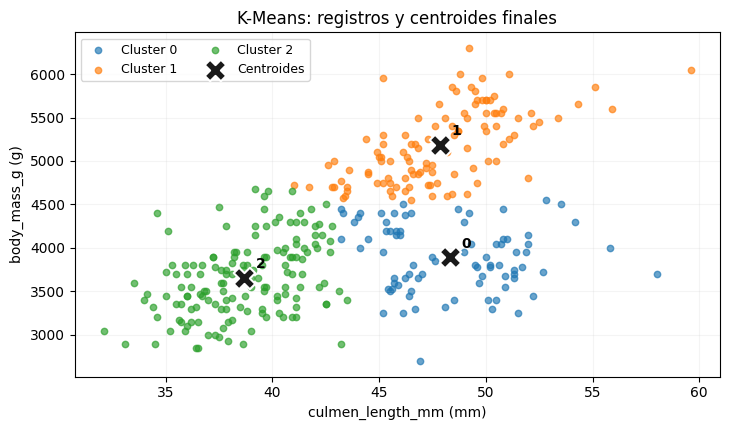

,K,Silhouette
0,3,0.467


Cluster,0,1,2
Especie real,,,
Adelie,5,4,142
Chinstrap,61,1,6
Gentoo,15,105,3


In [27]:
silueta = silhouette_score(X_escalado, grupos)  # Complete: agregue grupos
centros_originales = escalador.inverse_transform(modelo.cluster_centers_)

apoyo_visual.mostrar_clusters(X, grupos, centros_originales, columnas)
display(pd.DataFrame({"K": [k], "Silhouette": [round(silueta, 3)]}))
display(pd.crosstab(preparados["species"], grupos, rownames=["Especie real"], colnames=["Cluster"]))

### Preguntas A · K-Means

**A1.** ¿Qué es el **dominio de entrada** de K-Means? Identifique `X` y explique por qué no se utilizó `species` para entrenar.

*Respuesta:* El dominio de entrada de k-means recibe unicamente registros y caracteristicas numéricas, más no especies o datos tipo cadenas, es por ello que X corresponden a los datos de masa y milimetros de pico de un pingüino.

**A2.** ¿Qué ocurre con los `NaN` y cómo cambia el conjunto entre eliminarlos o rellenarlos? ¿Por qué también fue necesario escalar?

*Respuesta:* Los NaN al eliminarlos no afecta las medias ni los registros ya existentes, en cambio al rellenarlos existe un leve cambio con las estadisticas, que si bien pueden parecer "pequeño", no representan los datos originales.Y fue necesario escalar, ya que los números de la masa de los pingüinos al ser mucho mayor que los datos de la medida de los picos de los pingüinos, la masa podia dominar a los mm.

**A3.** Explique cómo se asignan registros y se mueven los centroides. Repita el entrenamiento con `k=5`: ¿qué cambió respecto de `k=3`?

*Respuesta:* Los registros se asignan según la cantidad de k grupos que se indiquen, entre los k grupo, los puntos se agruparan al grupo más cercano y una vez que los puntos se vayan integrando, el centroide de cada grupo se irá moviendo segun el promedio de las coordenadas de los puntos que estén ingresando en ese grupo.

**A4.** ¿Qué dicen Silhouette y la tabla especies–clusters? ¿Tener tres grupos implica haber identificado las tres especies?

*Respuesta:* Lo que se indica con el silhouette es la cohesión y separación de los grupos, donde 1 es mayor separación y 0 es una mala asignación, y como el silhouette con 3 grupos es de 0.467, mas cercano a 0 que a 1, podemos deducir que existe una mala asiganción de grupos, además con la tabla especies-cluster podemos notar que no están del todo parejos entre sí.

## B. Aprendizaje por refuerzo · Aprender mediante decisiones

En **CartPole** un carro debe mover una barra para que no caiga. En lugar de recibir un CSV con respuestas correctas, el **agente** observa un **estado**, ejecuta una **acción** en el **entorno**, recibe una **recompensa** y observa el nuevo estado.

**Ciclo:** estado → política elige acción → entorno reacciona → nuevo estado + recompensa → nueva decisión.

El agente aprende una **política** (estrategia para elegir acciones), no un cluster. Aquí utilizaremos **PPO** (*Proximal Policy Optimization*).

In [28]:
import gymnasium as gym
from stable_baselines3 import PPO
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.monitor import Monitor

nombre_entorno = "CartPole-v1"  # Complete: escriba CartPole-v1
entorno = gym.make(nombre_entorno)

# Espacios permitidos por el entorno.
display(pd.DataFrame({"Observaciones": [str(entorno.observation_space)],
                      "Acciones": [str(entorno.action_space)]}))

,Observaciones,Acciones
0,Box([-4.8 -inf -0.41887903 ...,Discrete(2)


### B1. Estado, acción, paso y episodio

El **estado** contiene cuatro números: posición y velocidad del carro, ángulo y velocidad angular de la barra. El agente elige `0` (izquierda) o `1` (derecha).

Un **paso** (`step`) es una acción y su consecuencia. Varios pasos forman un **episodio**, que termina cuando cae la barra, el carro se sale o llega al límite de **500 pasos**.

Aquí el entorno otorga **+1 por cada paso**, incluido el último; si el episodio dura 120 pasos, su recompensa total es 120. No equivale a 120 % de precisión. `reset()` empieza un episodio y `step(accion)` devuelve el nuevo estado, recompensa y señales de finalización.

In [30]:
estado, _ = entorno.reset(seed=17)
accion = 1  # Complete: pruebe 0 (izquierda) y luego 1 (derecha)
nuevo_estado, recompensa, terminado, truncado, _ = entorno.step(accion)

display(pd.DataFrame({"Acción": [accion],
                      "Ángulo previo (°)": [round(float(np.degrees(estado[2])), 2)],
                      "Ángulo nuevo (°)": [round(float(np.degrees(nuevo_estado[2])), 2)],
                      "Recompensa": [recompensa]}))

,Acción,Ángulo previo (°),Ángulo nuevo (°),Recompensa
0,1,0.33,0.32,1.0


### B2. ¿Qué significa entrenar PPO?

PPO utiliza las experiencias del agente para **ajustar una política de decisiones** (en este caso, una red neuronal).

- `total_timesteps`: cantidad aproximada de **interacciones con el entorno** durante `learn()`.
- `n_steps`: pasos de experiencia que PPO **recoge antes de actualizar** su política (por entorno).
- `n_epochs`: veces que PPO **revisa ese lote de experiencias** durante una actualización. **No** es la cantidad de episodios.

Un episodio puede terminar en 15 o en 300 pasos. Un entrenamiento contiene muchos episodios y actualizaciones.

In [34]:
epocas_por_actualizacion = 5  # Complete: pruebe 5
agente = PPO("MlpPolicy", entorno, n_steps=512, batch_size=64,
             n_epochs=epocas_por_actualizacion, verbose=0,
             seed=42, device="cpu")
pesos_inicio = apoyo_visual.guardar_politica(agente)

### B3. Evaluar antes de entrenar

`evaluate_policy(modelo, entorno, n_eval_episodes=N, deterministic=True)` ejecuta **N episodios** y devuelve **media y desviación** de sus recompensas.

Ejemplo: si tres episodios entregan **20, 40 y 60**, la recompensa media es **40**. Un episodio aislado no representa necesariamente el rendimiento general. Una política sin entrenamiento puede equilibrar la barra durante algunos pasos por casualidad.

In [35]:
episodios_evaluacion = 5  # Complete: use 5 episodios
entorno_evaluacion = Monitor(gym.make(nombre_entorno))
media_inicio, desv_inicio = evaluate_policy(
    agente, entorno_evaluacion,
    n_eval_episodes=episodios_evaluacion, deterministic=True
)
display(pd.DataFrame({"Etapa": ["Antes"], "Media": [round(media_inicio, 1)],
                      "Desviación": [round(desv_inicio, 1)]}))

,Etapa,Media,Desviación
0,Antes,102.4,14.5


### B4. Entrenar en dos etapas y seguir aprendiendo

`learn(total_timesteps=N)` provoca aproximadamente **N interacciones** y actualiza la política. Primero entrenaremos 4.096 pasos y después **continuaremos** otros 8.192 con `reset_num_timesteps=False`: no se parte de cero.

Guardaremos el estado de la política tras cada etapa para visualizarla después. El resultado puede fluctuar; la recompensa media de varios episodios importa más que un único recorrido.

In [36]:
pasos_primera_etapa = 4096  # Complete: use 4096
agente.learn(total_timesteps=pasos_primera_etapa, reset_num_timesteps=False)
pesos_mitad = apoyo_visual.guardar_politica(agente)
media_mitad, desv_mitad = evaluate_policy(
    agente, entorno_evaluacion,
    n_eval_episodes=episodios_evaluacion, deterministic=True
)
display(pd.DataFrame({"Etapa": ["Parcial"], "Media": [round(media_mitad, 1)],
                      "Desviación": [round(desv_mitad, 1)]}))

,Etapa,Media,Desviación
0,Parcial,179.6,33.6


In [37]:
pasos_segunda_etapa = 8192  # Complete: use 8192
agente.learn(total_timesteps=pasos_segunda_etapa, reset_num_timesteps=False)
pesos_final = apoyo_visual.guardar_politica(agente)
media_final, desv_final = evaluate_policy(
    agente, entorno_evaluacion,
    n_eval_episodes=episodios_evaluacion, deterministic=True
)
resumen = pd.DataFrame({"Etapa": ["Antes", "Parcial", "Final"],
                        "Media": [media_inicio, media_mitad, media_final],
                        "Desviación": [desv_inicio, desv_mitad, desv_final]})
display(resumen.round(1))

,Etapa,Media,Desviación
0,Antes,102.4,14.5
1,Parcial,179.6,33.6
2,Final,457.4,77.9


In [38]:
# predict(estado) elige una acción sin reentrenar la política.
estado, _ = entorno.reset(seed=17)
determinista = True  # Complete: use True
accion, _ = agente.predict(estado, deterministic=determinista)
estado_nuevo, recompensa, terminado, truncado, _ = entorno.step(int(accion))
display(pd.DataFrame({"Acción": [int(accion)], "Recompensa": [recompensa],
                      "Ángulo nuevo (°)": [round(float(np.degrees(estado_nuevo[2])), 2)]}))

,Acción,Recompensa,Ángulo nuevo (°)
0,0,1.0,0.32


### B5. Explorar el comportamiento a distintas etapas

Esta visualización **sí utiliza las políticas guardadas** en tres momentos reales del entrenamiento. Elija **Antes**, **Parcial** o **Final**, cambie **Caso inicial** y mueva **Paso** para observar el carro, la barra, la acción y la recompensa acumulada.

Se reproduce **un episodio bajo la misma condición inicial** para cada etapa. La tabla anterior resume **varios episodios** y es la referencia más confiable para evaluar el modelo.

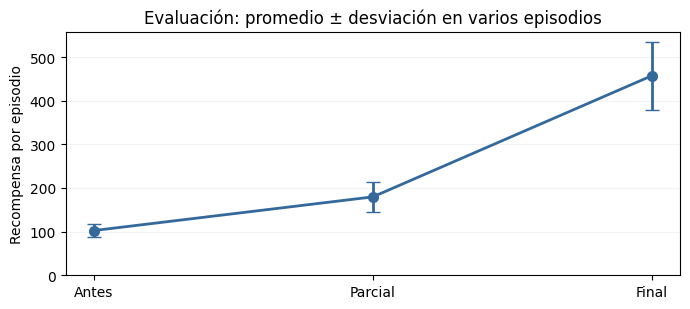

In [39]:
apoyo_visual.grafico_recompensas(resumen)
apoyo_visual.explorar_cartpole(agente, {
    "Antes de entrenar": pesos_inicio,
    "Entrenamiento parcial": pesos_mitad,
    "Entrenamiento final": pesos_final
})

### Preguntas B · Aprendizaje por refuerzo

**B1.** Identifique agente, entorno, estado, acciones y recompensa de CartPole. ¿Quién define las recompensas y qué significa obtener 120 puntos?

*Respuesta:* El agente: es la inteligencia artificial.
El entorno: puede ser el carro junto con la barra y la pista.
Estado: es la información que se nos entrega ya sea la posición, la velocidad del carro o el angulo y velocidad de la barra, etc.
Las acciones: aquellas acciones que podemos tomar que es empujar el carro hacia la izquierda o derecha.
Recompensa:son los puntos que se otorgan por cada paso cumplido sin que la barra se desequilibre, y que se obtengan 120 puntos, significa que el carro avanzó 120 pason sin que la barra que lleva encima se desequilibrara.

**B2.** Diferencie **paso**, **episodio**, `total_timesteps` y `n_epochs`. ¿Qué hace PPO y qué aprende su política?

*Respuesta:* El paso: es la unidad en la que se mide el sistema (pasos hasta que se desequilibre el sistema o se salga del límite).
Episodio: Un episodio es desde que parte el carro con la barra equilibrada hasta que esta se desequilibra o el carro supera el limite del sistema.
total_timesteps: Es la cantidad total de pasos que se consiguieron el el episodio.
n_epochs: es la cantidad de veces que el sistema de inteligencia artificial repasa los datos de una jugada para así obtener información y aprender bien de ella.

**B3.** Compare las etapas inicial, parcial y final. ¿Qué significa la **recompensa media**? ¿Por qué una sola animación no demuestra que un modelo haya mejorado?

*Respuesta:* La recompensa media, es como indica la palabra, la media o promedio de recompensas que se obtienen luego de varias jugadas y en diferentes etapas del juego, esto indica que una sola animación no demuestra que el modelo haya mejorado, pues solo se estaría tomando un par de información que suponemos correcta, pero si seguimos probando y obteniendo mas pares de datos notaremos una estadística que nos indicaria una mejora del modelo.

## C. Integración · Comparar paradigmas de Machine Learning

**C1. Dominio de los modelos.** ¿Qué tipo de información necesita una regresión lineal, un clasificador supervisado, K-Means y PPO? ¿Qué diferencia hay entre datos de entrada, etiquetas y recompensas?

*Respuesta:* Una regresión lineal necesita de datos numéricos, un clasificador supervisado necesita de características de entrada y de categorias, un K-Means necesita de características numéricas para calcular distancias y un PPO necesita de un entornointeractivo que le proporcione datos de aprendizaje. Y la diferencia qué los datos de entrada es la información que recibe el sistema, las etiquetas es algo que esta definido en el modelo y que el sistema intenta de identificar cual es segun las etiquetas que tiene y las recompensas es un dato numérico que indica una retroalimentación según el aprendizaje que está teniendo.

**C2. Flujo.** Compare **analizar → preparar → entrenar → predecir o actuar → evaluar** para regresión/clasificación, K-Means y PPO. ¿De dónde vienen sus datos de entrenamiento y cuál es su salida?

*Respuesta:* Para una regresión/clasificacón los datos correspondes a una base de datos etiquetada para obtener un número o probabilidad, en un K_Means los datos vienen de datos estaticos sin necesariamente ser etiquetados y su salida corresponde a una etiqueta del centroide que se le asigno a algún dato y en un PPO los datos provienen de un entorno interactivo como un simulador que tiene como salida una distribucion de los datos obtenidos.

**C3. Aplicaciones.** Proponga un caso real para **regresión, clasificación, clustering y aprendizaje por refuerzo**. Justifique qué datos necesita y por qué elegiría ese enfoque.

*Respuesta:* Creo que puede servir, pero podria servir para agrupar conjuntos de minerales y separarlas con caracteristicas que serían ingresadas en los datos, como el volumen, ley del mineral, etc. De modo que se pueda estimar el precio de la extracción y decidir si es beneficiaria su extracción, etc.

**C4. Relación entre enfoques.** ¿Podrían combinarse dos enfoques en una misma aplicación? Describa un ejemplo y qué función cumple cada uno.

*Respuesta:* Si podrian combinarse dos enfoques distintos y podría ser muy util, por ejemplo con K-means detectar los gustos de los lectores virtuales y con ello agruparlos en base al contenido que leen y posteriormente, con un PPO un agente decide que recomendaciones de libro entregarle.

---

**Entrega:** responda brevemente (2 a 4 líneas por pregunta). Conserve los gráficos. Un notebook ejecutado, con sus gráficos, resultados y respuestas. No se evalúa memorizar código; se evalúa comprender el proceso y justificar decisiones.